In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import dask

In [2]:
var = 't2max'
var_file = 't2m'
year_min = 2000
year_max = 2012
year_ref_min = 1985
year_ref_max = 2014

In [3]:
# Only keep years with 365 days, remove leap year day
def remove_leap_days(ds):
    # Get day-of-year for each time step
    day_of_year = ds['time'].dt.dayofyear
    # Keep only days <= 365 (i.e., remove Feb 29)
    ds_corrected = ds.sel(time=day_of_year <= 365)
    return ds_corrected

In [4]:
def compute_mse_year(file_nn, file_ref, var_file):

    ds_ref = xr.open_dataset(file_ref, chunks=chunks)[var_file]
    #ds_ref = ds_ref.rename({'valid_time': 'time'})
    # remove Feb 29
    ds_ref = remove_leap_days(ds_ref) #leap years to 365
    
    ds_nn = xr.open_dataset(file_nn, chunks=chunks)[var_file]
    #time dimension of NN output is wrong, with constant year time dimension. Correct it:
    ds_nn['time'] = ds_ref['time']

    #mask ocean data
    ds_nn = xr.where(np.isnan(ds_ref),np.nan,ds_nn)
    
    # Align
    ds_nn, ds_ref = xr.align(ds_nn, ds_ref)

    # Compute squared error lazily
    mse = ((ds_nn - ds_ref) ** 2).sum(dim="time", skipna=True)

    valid = (~np.isnan(ds_nn)) & (~np.isnan(ds_ref))
    n = valid.sum("time")

    return mse, n

In [5]:
chunks = {"time": 30, "lat": 150, "lon": 150}

In [6]:
path_original='/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/'+var+'/highres/anomalies/'
path_NN='/work/uo1075/u241308/ML_downscaling/code/climatereconstructionAI/evaluations/'

tasks = []
for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}era5_land_{var}_daily_{year}_europe_anomalies_ref_{year_ref_min}_{year_ref_max}_lowres_values_in_highres_grid.nc_output.nc"
    file_ref = f"{path_original}era5_land_{var}_daily_{year}_europe_anomalies_ref_{year_ref_min}_{year_ref_max}.nc"

    #file_nn = f"{path_NN}era5_{var}_{year}_europe_crai_HR_cnn_output.nc"
    #file_ref = f"{path_original}era5_land_{var}_daily_{year}_europe_original.nc"

    task = dask.delayed(compute_mse_year)(file_nn, file_ref, var_file)
    tasks.append(task)

results = dask.compute(*tasks)

sum_sq = sum(r[0] for r in results)
n_total = sum(r[1] for r in results)

rmse = np.sqrt(sum_sq / n_total)

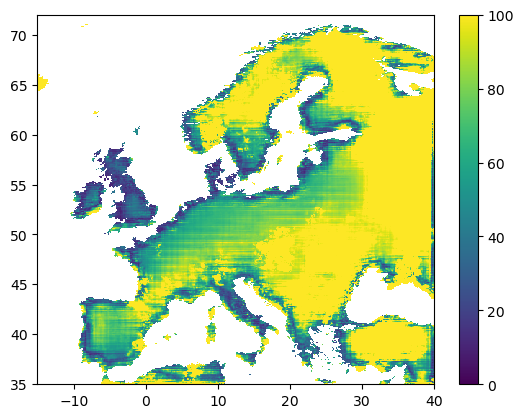

In [11]:
plt.pcolormesh(rmse.longitude,rmse.latitude,rmse,vmin=0,vmax=100)
plt.colorbar()